---
## **0. 준비**
---

In [20]:
%%html
<style>
    body {
        /* change --vscode-font-family if it's different on your system */
        --vscode-font-family: "SeoulNamsanC";
    }
</style>

In [1]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import GoogleGenerativeAI

In [32]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from IPython.display import display, Markdown

In [3]:
import config
config.set_environment()

---
## **LangGraph의 기본 원리**
---

- LangGraph는 LangChain 회사에서 개발한 워크플로 제어 및 오케스트레이션 프레임워크임.
- 별도의 워크프레임이 필요한 이유는 에이전트 기반 워크플로 구성에서 알 수 있을 것.
- **LangGraph 요약 :**
    - 비순환 그래프(DAG)가 아니라, **순환 주기를 허용**
    - 기본적으로 **스트리밍을 지원**
    - 생성형 AI에 특화된 **미리 제작된 루프와 컴포넌트**(예. 인간 중재 기능 등)를 제공
    - **세분화된 실행 흐름 제어**가 가능한 풍부한 API

- (참고) 방향성 비순환 그래프(DAG, Directed Acyclic Graph)
    - 그래프의 에지(노드 간 연결선)는 방향성을 가지며, **노드 A에서 B로의 연결과 노드 B에서 A로의 연결이 서로 다름**
    - DAG는 순환 구조를 갖지 않음
    - 즉, 어떤 노드에서 시작해 방향성 에지를 따라 이동했을 때 **다시 같은 노드로 돌아오는 경로가 존재하지 않음**
    - DAG는 데이터 엔지니어링 워크플로 모델로 자주 사용 : 노드는 작업(task)을 나타내고, 에지는 작업 간의 의존 관계를 나타냄. 예를 들어, A -> B는 노드 B를 실행하려면 노드 A의 출력이 필요하다는 뜻. 

---
### **상태 관리(state management)**
- '그래프(graph)'와 '워크플로' 용어를 동일한 의미로 사용하자.
- 그래프는 노드와 노드간의 에지로 구성, **노드는 워크플로의 컴포넌트이며, 워크플로는 상태(state)를 갖음**
- **상태(state) :**
    1. 상태는 사용자 입력과 이전 계산 결과를 추적하여 노드(워크플로의 컴퍼넌트)들이 현재 상황을 인지하도록 함
    2. 상태를 통해 워크플로 실행을 언제든지 중단하고 저장할 수 있음
    3. 노드(워크플로의 컴퍼넌트)가 상태를 업데이트하면 워크플로 동작을 변경할 수 있기 때문에, 상태는 워크플로를 진정한 상호작용형으로 만듦
    - **간단히 말해서, 상태를 파이썬 딕셔너리라고 생각하면 된다. 노드(컴퍼넌트)는 이 딕셔너리를 처리하는 파이썬 함수다. 노드는 딕셔너리를 입력으로 받아서 워크플로의 상태에서 업데이트할 키와 값을 포함한 새로운 딕셔너리를 반환**

In [4]:
# 간단한 예제: 노드들이 공유할 상태의 키 이름과 값의 타입을 정의합니다.
# 스키마는 데이터의 설계도입니다. 이 셀에서는 실제 공고나 지원서 내용을 생성하지 않습니다.

from typing import TypedDict                                                #딕셔너리의 키별로 서로 다른 값의 타입을 명시할 수 있는 TypedDict을 로딩

# TypedDict를 기반으로 상태 스키마를 선언합니다. 실제 상태 값은 일반 파이썬 딕셔너리입니다.
# 타입 힌트는 정적 분석을 돕지만, TypedDict 자체가 실행 중 값의 타입을 검사하거나 변환하지는 않습니다.
class JobApplicationState(TypedDict):
    job_description: str    #채용 공고 원문을 담는 문자열 키. 그래프 실행 시 입력으로 전달하고 분석 노드가 읽게 됨.
    is_suitable: bool       #공고의 적합 여부를 담는 불리언(True/False) 키. 분석 노드가 계산해 갱신.
    application: str        #생성된 지원서 내용을 담는 문자열 키. 지원서 생성 노드가 갱신.

# 위의 ': str', ': bool'은 타입 선언이며 기본값 대입이 아닙니다. 키에 값이 자동으로 채워지지 않습니다.
# 기본 TypedDict는 정적 타입 검사에서 세 키를 모두 요구합니다(total=True가 기본값).
# 다만 LangGraph는 입력으로 상태의 일부 키를 받고, 이후 노드가 나머지 키를 채우는 실행을 지원합니다.
# 예: graph.invoke({"job_description": "채용 공고 내용"}) — graph를 만든 다음 셀 이후에 실행합니다.
# 아직 채워지지 않은 키를 노드에서 state["키"]로 읽으면 KeyError가 발생할 수 있습니다.


> - `TypedDict`는 파이썬의 타입 생성자로, **미리 정의된 키 집합을 가진 딕셔너리를 정의함**
> - **각 키는 고유한 타입을 가질 수 있으며**, Dict[str, str]처럼 모든 값이 동일한 일반 딕셔너리와 다름
> - **LangGraph의 상태 스키마는 TypedDict 외에도 데이터 클래스나 Pydantic 모델을 사용해 정의할 수 있음**

In [5]:
# 스키마를 정의했으니 간단한 워크플로를 구성해보자
"""
- 2개의 파이썬 함수를 워크플로의 컴퍼넌트(노드)로 만듦
- 상태 스키마를 정의 -> 노드와 에지를 추가
"""

from langgraph.graph import StateGraph, START, END                          #StateGraph는 상태를 공유하는 그래프의 설계 도구

# 첫 번째 노드 함수, 실행 시점의 그래프 상태 딕셔너리를 state 인자로 전달받음.
def analyze_job_description(state):
    print("...Analyzing a provided job description...")
    return {"is_suitable": len(state["job_description"])>100}               #공고 문자열의 길이가 100자를 초과하면 True, 아니면 False를 반환, 전체 상태를 다시 반환할 필요 없이 변경할 키만 반환, 여기서는 is_suitable 값을 갱신.

# 두 번째 노드 함수, 앞 노드의 결과가 반영된 상태를 받음
def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application"}                         #실제 지원서를 생성하는 대신 고정된 예시 문자열을 application 키의 새 값으로 반환.

# 앞 셀에서 정의한 JobApplicationState를 상태 스키마로 지정하여 그래프 설계 객체를 만듦.
builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)        #첫 번째 인자는 그래프에서 사용할 노드 이름, 두 번째 인자는 실행할 함수 객체, 함수 이름 뒤에 ()를 붙이지 않음 -> 지금 호출하는 것이 아니라 실행할 함수를 등록하기 때문.
builder.add_node("generate_application", generate_application)

builder.add_edge(START, "analyze_job_description")                          #그래프 실행이 시작되면 공고 분석 노드로 이동하도록 연결.
builder.add_edge("analyze_job_description", "generate_application")         #분석이 끝나면 지원서 생성 노드로 무조건 이동. is_suitable이 False여도 생성 노드는 실행, 적합 여부에 따라 실행을 나누려면 별도로 조건부 에지(add_conditional_edges)를 구성해야 함.
builder.add_edge("generate_application", END)                               #지원서 생성 노드가 끝나면 워크플로를 종료.

# 설계한 노드와 연결을 검사하고 실행 가능한 그래프로 만듦. compile() 자체는 노드를 실행하지 않습니다.
graph = builder.compile()                                                   #이후 graph.invoke({"job_description": "공고 내용"})를 호출하면 위 순서로 실행하고 최종 상태를 반환.


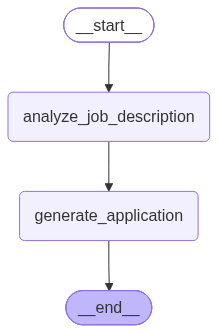

In [6]:
# 워크플로 시각화
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

> - 노드가 상태를 바꾸려면, 반드시 업데이트할 키와 값이 들어 있는 딕셔너리를 반환해야함.
> - 노드는 상태에서 최소한 하나의 키를 수정해야함. 

In [7]:
# graph 인스턴스 자체는 Runnable(정확히는 Runnable을 상속). 
# 초기 상태를 딕셔너리로 넘기면, 실행 결과로 최종 상태를 딕셔너리 형태로 받을 수 있음
res = graph.invoke({"job_description": "fake_jd"})
print(res)

...Analyzing a provided job description...
...generating application...
{'job_description': 'fake_jd', 'is_suitable': False, 'application': 'some_fake_application'}


- LangGraph는 워크플로를 **슈퍼스텝**이라는 단위로 실행
- **슈퍼스텝은 여러 개의 노드를 대상으로 한 하나의 반복 실행 단위를 의미**
- 슈퍼스텝은 여러 노드를 병렬로 실행하고, 그 결과를 중앙 그래프 상태에 반영하는 역할을 함

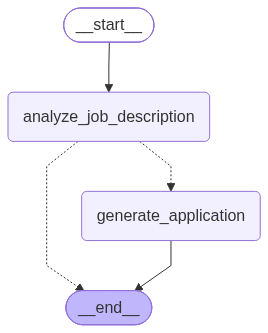

...Analyzing a provided job description...
{'job_description': 'fake_jd', 'is_suitable': False}


In [8]:
# 조건부 에지 실습으로 발전
# 현재 상태에 따라 실행 흐름을 다른 노드로 동적으로 전달 가능
# 조건부 에지는 현재 상태를 입력받아 실행할 노드의 이름을 문자열로 반환하는 파이썬 함수

from typing import Literal

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description",
                             is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

res = graph.invoke({"job_description": "fake_jd"})                          #위 예시에서는 generate_application 노드를 거치지 않고 바로 END로 진행 -> 'application' 키와 값이 반환되지 않음(둘다 없는 거임)
print(res)

말씀하신 실행에서 **초기 입력에도 `application`을 넣지 않았고, 생성 노드도 거치지 않았다면 최종 딕셔너리에는 키와 값이 모두 없습니다.**

```python
{"job_description": "fake_jd", "is_suitable": False}
```

상태 스키마의 다음 선언은 **사용할 키와 타입을 정의할 뿐, 실제 키나 기본값을 생성하지 않습니다.**

```python
application: str
```

다음 세 상태는 서로 다릅니다.

| 상태 | 딕셔너리 표현 |
|---|---|
| 키가 없음 | `{}` |
| 키가 있고 값이 `None` | `{"application": None}` |
| 키가 있고 값이 빈 문자열 | `{"application": ""}` |

따라서 지금 상황은 **스키마에는 `application`이 정의되어 있지만, 이번 실행에서는 값이 입력·생성되지 않아 최종 상태에 해당 키가 없다**고 서술하면 정확.

```python
"application" in result  # 키 존재 여부 확인
```

단, 처음부터 `application` 값을 입력했다면 생성 노드를 건너뛰어도 기존 값은 유지됩니다.

현재 저장된 파일에는 아직 이전 오타와 코드가 남아 있어, 최신 출력 자체는 확인하지 못했습니다.

> - Literal 타입 힌트를 사용했는데, 이는 LagnGraph가 조건부 에지를 생성할 때 어떤 목적지 노드와 연결할지 판단할 때 사용
> - **만약 타입 힌트를 사용하지 않으면, `add_conditional_edges` 함수에 목적지 노드들의 목록을 직접 넘겨야함**
> - 타입 힌트도 없고 목적지도 명시하지 않으면, LangGraph는 소스 노드를 그래프에 있는 모든 노드와 연결하게 됨

---
### **리듀서**
- 상태의 모든 키에는 일련의 값들이 존재하며, 함수형 프로그래밍의 관점에서 이 값들의 시퀀스에 reduce 함수 적용 가능
- LangGraph의 기본 리듀서는 항상 최종 값을 새 값으로 대체
> 노드들이 생성하는 사용자 정의 액션들을 추적하고 세 가지 옵션을 비교하고 싶다고 가정 

<hr style="border:0;border-top:1.5px dashed gray;">

#### **첫 번째 옵션 : 해당 키에 이미 값이 존재한다면, 새로운 값으로 대체**

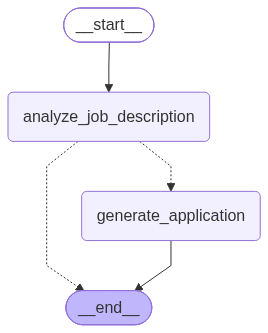

In [9]:
# This first option is to use a default reducer that replaces the values in the state:

from typing import TypedDict
class JobApplicationState(TypedDict):
    job_description: str   
    is_suitable: bool       
    application: str
    actions: list[str]

def analyze_job_description(state):
    print("...Analyzing a provided job description ...")
    result = {
        "is_suitable": len(state["job_description"]) < 100,
        "actions": ["actions1"]    }
    return result

def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application", "actions":["action2"]}

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)

builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description", 
                              is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

- **아래 코드는 출력 확인을 위한 예시임**
    - 그래프를 **실행하면서 상태가 변하는 과정을 차례로 출력**
    - **`stream_mode="values"`** 이므로 노드의 반환 딕셔너리만이 아니라, **업데이트가 반영된 전체 상태를 봄**
    - 아래 예제는 순차 실행이라 각 노드 처리 후의 상태가 보임, **일반적으로는 각 슈퍼스텝의 상태**
    - 이 셀은 기존 결과를 조회하는 것이 아니라, **그래프를 새로 실행하므로 노드의 작업도 다시 수행**

In [10]:
# astream()은 비동기 스트림을 반환. async for는 새 결과가 도착할 때마다 chunk에 넣어 반복.
# chunk는 개발자가 정한 변수 이름이며, 여기서는 답변의 토큰 조각이 아닌 전체 상태 딕셔너리.
# 주피터/IPython은 셀 최상위의 async for를 지원. 일반 .py에서는 보통 async def 안에서 사용.

async for chunk in graph.astream(
    input={"job_description":"fake_jd"},                                    #그래프의 초기 입력. 공고 내용만 지정하고 나머지 키는 실행되는 노드가 채움.
    stream_mode="values"                                                    #values: 초기 상태와 이후 슈퍼스텝별 전체 상태를 받음.
                                                                            #updates를 사용하면 보통 {노드명: 해당 노드가 반환한 변경값} 형태로 받음.
):  # astream() 인자 목록을 닫고, 각 결과를 처리할 반복문 본문을 시작합니다.
    print(chunk)                                                            #현재 시점의 전체 상태를 출력, 없는 키가 None으로 자동 채워지는 것은 아님.
    print("\n\n")

# 이 예시의 상태 흐름: 초기 입력 → 공고 분석 결과 반영 → 지원서 생성 결과 반영.
# 앞 셀에서는 문자열 길이 < 100이면 적합하다고 판단하므로, "fake_jd"는 지원서 생성 노드로 진행.
# actions는 누적 리듀서가 없는 일반 상태 키이므로 ['actions1']이 ['action2']로 교체.


{'job_description': 'fake_jd'}



...Analyzing a provided job description ...
{'job_description': 'fake_jd', 'is_suitable': True, 'actions': ['actions1']}



...generating application...
{'job_description': 'fake_jd', 'is_suitable': True, 'application': 'some_fake_application', 'actions': ['action2']}





> 핵심은 **`stream_mode="values"`가 각 노드의 반환값만 보여주는 것이 아니라, 변경 사항이 반영된 전체 상태를 보여준다**는 점입니다.
> `async for`, `astream()`, `chunk`, `values`와 `updates`의 차이, `actions`가 누적되지 않고 교체되는 이유도 설명했습니다.

<hr style="border:0;border-top:1.5px dashed gray;">

#### **두 번째 옵션 : Annotated 타입 힌트와 add 메서드를 함께 사용**

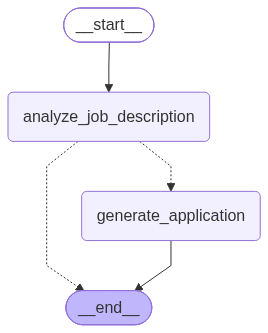

In [11]:
# 이미 상태에 리스트 값이 존재하고 노드가 새 리스트 값을 생성하는 경우에 두 리스트를 연결
# use add method as a reducer:

from typing import TypedDict, Annotated, Optional
from operator import add

class JobApplicationState(TypedDict):
    job_description: str   
    is_suitable: bool       
    application: str
    actions: Annotated[list[str], add]

def analyze_job_description(state):
    print("...Analyzing a provided job description ...")
    result = {
        "is_suitable": len(state["job_description"]) < 100,
        "actions": ["actions1"]    }
    return result

def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application", "actions":["action2"]}

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)

builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description", 
                              is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
async for chunk in graph.astream(
    input={"job_description":"fake_jd"},                                    
    stream_mode="values" ):
                                                                                                                            
    print(chunk)                                                            
    print("\n\n")

{'job_description': 'fake_jd', 'actions': []}



...Analyzing a provided job description ...
{'job_description': 'fake_jd', 'is_suitable': True, 'actions': ['actions1']}



...generating application...
{'job_description': 'fake_jd', 'is_suitable': True, 'application': 'some_fake_application', 'actions': ['actions1', 'action2']}





<hr style="border:0;border-top:1.5px dashed gray;">

#### **세 번째 옵션: 사용자 정의 리듀서**

리듀서는 **기존 상태 값(`left`)과 새 업데이트(`right`)를 받아, 상태에 저장할 결과를 반환하는 함수**다. 아래 예제는 기존 문자열 리스트에 문자열 하나 또는 문자열 리스트를 이어 붙인다.

```python
from typing import Annotated, Optional, Union


def my_reducer(
    left: list[str],
    right: Optional[Union[str, list[str]]],
) -> list[str]:
    if right:
        return left + [right] if isinstance(right, str) else left + right
    return left
```

**1. 타입 관련 도구 불러오기**

```python
from typing import Annotated, Optional, Union
```

| 도구 | 의미 | 이 예제에서의 역할 |
|---|---|---|
| `Annotated[T, 정보]` | 타입에 추가 정보를 연결 | 상태 키에 리듀서를 등록할 때 사용. 함수 정의 자체에는 사용하지 않음 |
| `Optional[T]` | `T` 또는 `None` 허용 | 새 업데이트가 `None`일 수 있음을 표현 |
| `Union[A, B]` | `A` 또는 `B` 허용 | 새 업데이트가 문자열 또는 리스트일 수 있음을 표현 |

`Optional`은 **인자를 생략해도 된다는 뜻이 아니다.** 기본값 `= None`을 지정하지 않았으므로 함수 호출 시 `right` 인자는 전달해야 한다. 타입 힌트 자체가 실행 중 값을 검사하거나 자동 변환하지는 않는다.

**2. 함수의 입력과 반환 타입**

```python
def my_reducer(
    left: list[str],
    right: Optional[Union[str, list[str]]],
) -> list[str]:
```

- `left`: 현재까지 누적된 문자열 리스트. 예: `["action1"]`.
- `right`: 새로 들어온 문자열 하나, 문자열 리스트 또는 `None`.
- **`Optional[Union[str, list[str]]]`: `str | list[str] | None`과 같은 의미.**
- `-> list[str]`: 반환 결과도 문자열 리스트라는 타입 힌트.

**3. 업데이트가 비어 있는지 검사**

```python
if right:
```

`right`의 참/거짓을 검사한다. 기대한 입력 타입 중 `None`, 빈 문자열 `""`, 빈 리스트 `[]`는 거짓으로 평가되므로 추가하지 않고 마지막 `return left`로 이동한다. 단순히 `None`만 검사하는 코드와는 다르다.

**4. 문자열과 리스트를 구분하여 연결**

```python
return left + [right] if isinstance(right, str) else left + right
```

조건부 표현식의 문법은 `A if 조건 else B`다. **조건을 먼저 검사하고 A 또는 B 중 하나만 계산**한다.

| 조건 | 수행 내용 |
|---|---|
| `isinstance(right, str)`이 참 | 문자열을 `[right]`로 감싸 원소 하나짜리 리스트로 만든 뒤 `left`에 연결 |
| 거짓 | 기대한 타입상 리스트로 보고 `left + right`로 연결 |

예를 들어 문자열 `"abc"`는 `["abc"]`로 변환한다. 문자별로 나누는 `list("abc")`와 다르다. 문자열을 리스트로 감싸는 이유는 리스트에 문자열을 그대로 `+`로 더할 수 없기 때문이다.

두 분기 모두 `+`로 **새 리스트를 만들며 기존 `left`를 직접 수정하지 않는다.** 중복 값도 제거하지 않는다.

위 한 줄은 다음 코드와 같은 의미다.

```python
if isinstance(right, str):
    return left + [right]
else:
    return left + right
```

**5. 업데이트가 비어 있으면 기존 값 유지**

```python
return left
```

추가할 내용이 없으면 기존 `left` 객체를 그대로 반환한다. 이 분기에서는 새 리스트를 만들거나 복사하지 않는다.

**입력별 결과 확인**

| 호출 | 결과 | 설명 |
|---|---|---|
| `my_reducer(["a"], "b")` | `["a", "b"]` | 문자열 하나 추가 |
| `my_reducer(["a"], ["b", "c"])` | `["a", "b", "c"]` | 리스트 연결 |
| `my_reducer(["a"], None)` | `["a"]` | 업데이트 없음 |
| `my_reducer(["a"], "")` | `["a"]` | 빈 문자열도 추가하지 않음 |
| `my_reducer(["a"], [])` | `["a"]` | 빈 리스트는 기존 값 유지 |
| `my_reducer(["a"], "a")` | `["a", "a"]` | 중복도 누적 |

**LangGraph 상태에 리듀서 연결하기**

상태 스키마에서 사용할 키를 다음처럼 선언한다.

```python
actions: Annotated[list[str], my_reducer]
```

`actions`의 저장 타입은 `list[str]`이고, 해당 키에 새 업데이트가 오면 `my_reducer`로 기존 값과 합친다는 뜻이다. **함수를 정의하는 것만으로 모든 상태 키에 자동 적용되지는 않는다.**


In [13]:
from typing import Annotated, Optional, Union


def my_reducer(
    left: list[str],
    right: Optional[Union[str, list[str]]],) -> list[str]:
    if right:
        return left + [right] if isinstance(right, str) else left + right
    return left


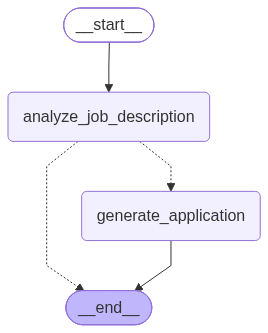

In [14]:
class JobApplicationState(TypedDict):
    job_description: str   
    is_suitable: bool       
    application: str
    actions: Annotated[list[str], my_reducer]

def analyze_job_description(state):
    print("...Analyzing a provided job description ...")
    result = {
        "is_suitable": len(state["job_description"]) < 100,
        "actions": ["actions1"]    }
    return result

def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application", "actions":["action2"]}

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)

builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description", 
                              is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
async for chunk in graph.astream(
    input={"job_description":"fake_jd"},                                    
    stream_mode="values" ):
                                                                                                                            
    print(chunk)                                                            
    print("\n\n")

{'job_description': 'fake_jd', 'actions': []}



...Analyzing a provided job description ...
{'job_description': 'fake_jd', 'is_suitable': True, 'actions': ['actions1']}



...generating application...
{'job_description': 'fake_jd', 'is_suitable': True, 'application': 'some_fake_application', 'actions': ['actions1', 'action2']}





<hr style="border:0;border-top:1.5px dashed gray;">

#### **기본 제공 리듀서: 주목 `add_messages`**
- LangGraph는 몇 가지 기본 제공 리듀서를 제공
- `add_messages`는 메시지를 효율적으로 병합, LLM 에이전트들로 구성된 노드들이 메시지 기반으로 작동하기 때문에 메세지 추적이 매우 중요
- 5장과 6장에서 보다 자세히 다룰 것

In [ ]:
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

# 더 상세한 사용 예시는 5장, 6장에서

# 방법 A : 메시지 키와 리듀서를 직접 선언
class JobApplicationState(TypedDict):
    ...
    messages: Annotated[list[AnyMessage], add_messages]

# 방법 B : `MessagesState`를 상속하여 간단히 선언
from langgraph.graph import MessagesState
class JobApplicationState(MessagesState):
    ...
# `MessagesState`에 `messages` 키와 리듀서가 이미 정의되어 있으므로 다시 선언하지 않음.
# 위 두 방법은 이 예제에서 같은 메시지 병합 설정을 갖음, 상속받는 쪽에 공고·지원서 등 필요한 다른 키를 추가하면 됨.

#### **33번 셀 미리 보기: 메시지 상태와 기본 제공 리듀서**

이 코드는 **여러 노드가 주고받는 메시지를 상태에 모으는 두 가지 방법**을 보여준다. 모델을 호출하거나 그래프를 실행하는 코드는 아니며, 메시지를 저장할 상태 스키마를 정의한다.

**임포트하는 이름의 정체와 목적**

| 이름 | 종류 | 목적 |
|---|---|---|
| `AnyMessage` | 타입 별칭 | `HumanMessage`, `AIMessage`, `SystemMessage`, `ToolMessage` 등 지원 메시지 타입을 함께 표현 |
| `add_messages` | 리듀서 함수 | 기존 메시지와 새 메시지를 ID를 기준으로 병합 |
| `MessagesState` | 미리 정의된 `TypedDict` 상태 스키마 | `messages` 키와 `add_messages` 설정을 기본 제공 |

`AnyMessage`는 메시지를 생성하는 클래스가 아니다. 실제 사용자 메시지는 `HumanMessage(content="질문")`, 모델 답변은 `AIMessage(content="답변")`처럼 만든다. 메시지 목록에는 서로 다른 역할의 메시지가 함께 들어갈 수 있다.

**방법 A: 메시지 키와 리듀서를 직접 선언**

```python
from typing import Annotated, TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class ApplicationStateExplicit(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    job_description: str
```

- `list[AnyMessage]`: 상태에 저장되는 값은 메시지 객체들의 리스트다.
- `Annotated[타입, 추가 정보]`: 여기서는 `list[AnyMessage]`에 리듀서 `add_messages`를 연결한다.
- `messages`: 노드가 이 키의 업데이트를 반환하면 LangGraph가 해당 리듀서로 기존 값과 합친다.
- 노드에서는 `return {"messages": [새_메시지]}`처럼 새 메시지만 반환할 수 있다.

**`add_messages`는 단순 리스트 덧셈과 무엇이 다른가?**

새 ID의 메시지는 뒤에 추가하지만, **기존 메시지와 같은 ID이면 그 위치의 메시지를 교체**한다. 문장 내용이 같다는 이유만으로 중복을 제거하지는 않는다. 지원되는 딕셔너리 형식의 입력을 메시지 객체로 변환하는 기능도 갖고 있다.

```python
from langchain_core.messages import HumanMessage, AIMessage

messages = [HumanMessage(content="안녕", id="u1")]

# 새 ID이므로 모델 답변이 뒤에 추가된다.
messages = add_messages(
    messages,
    [AIMessage(content="안녕하세요!", id="a1")],
)

# 같은 ID인 u1을 지정했으므로 첫 메시지를 교체한다. 전체 길이는 2로 유지된다.
messages = add_messages(
    messages,
    [HumanMessage(content="질문을 수정할게", id="u1")],
)

for message in messages:
    print(message.type, message.id, message.content)
```

예상 출력:

```text
human u1 질문을 수정할게
ai a1 안녕하세요!
```

이 예시는 메시지 병합만 확인하며 API를 호출하지 않는다. 내용을 교체한다고 뒤의 AI 답변까지 자동으로 다시 생성되는 것은 아니다.

**방법 B: `MessagesState`를 상속하여 간단히 선언**

```python
from langgraph.graph import MessagesState

class ApplicationStateBuiltIn(MessagesState):
    job_description: str
```

`MessagesState`에 `messages` 키와 리듀서가 이미 정의되어 있으므로 다시 선언하지 않는다. 위 두 방법은 이 예제에서 같은 메시지 병합 설정을 갖는다. 상속받는 쪽에 공고·지원서 등 필요한 다른 키를 추가하면 된다.

**교재 코드에서 주의할 부분**

```python
class JobApplicationState(TypedDict):
    ...
    messages: Annotated[list[AnyMessage], add_messages]

class JobApplicationState(MessagesState):
    ...
```

1. 두 선언은 **서로 다른 작성 방법을 나란히 보여준 예시**다. 같은 이름으로 연달아 실행하면 두 번째 클래스가 첫 번째 이름을 대체한다. 두 선언이 합쳐지는 것은 아니다.
2. `...`는 생략을 표시하는 `Ellipsis` 표현식이다. 이전 셀에서 선언한 `job_description`, `application` 등의 키를 자동으로 가져오지 않는다.
3. 이 셀을 그대로 실행한 뒤의 `JobApplicationState`는 두 번째 선언을 가리키며, 기본적으로 상속받은 `messages` 키만 갖는다. 기존 공고 처리 그래프를 다시 만들려면 필요한 공고 관련 키도 명시해야 한다.
4. 상태를 선언하는 것만으로 대화가 영구 저장되거나 모델에 자동 전달되지는 않는다. 노드에서 `state["messages"]`를 모델에 전달하고, 실행 간 저장에는 별도로 체크포인터 등을 설정한다.

[공식 문서: 그래프 상태의 메시지와 MessagesState](https://docs.langchain.com/oss/python/langgraph/graph-api#working-with-messages-in-graph-state)


---
### **그래프 구성하기**
- LangGraph를 통해 사용자 입력과 매개변수를 분리할 수 있음
- 서로 다른 LLM 공급자 간에 실험을 하거나, 사용자 정의 콜백을 전달할 수 있음
- **노드는 설정값을 두 번째 인자로 받아 사용 가능, 이 설정은 `RunnableConfig`의 인스턴스로 전달**
- `RunnableConfig` :
    - 실행 제어 설정을 관리할 수 있는 타입이 지정된 딕셔너리
    - 예를 들어, `recursion_limit` 변수로 최대 슈처스텝 수를 제어
    - 사용자 정의 매개변수를 설정 가능한 키 아래에 별도의 딕셔너리로 전달하는 기능도 제공

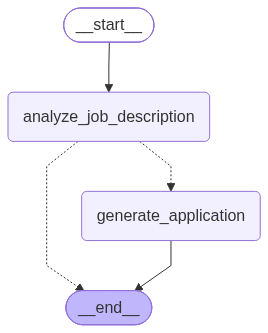

In [16]:
# How we can add configuration to our graph:
# LangGraph는 설정이 제공되지 않을 경우 기본 설정을 사용.
from langchain_core.runnables.config import RunnableConfig

class JobApplicationState(TypedDict):
    job_description: str   
    is_suitable: bool       
    application: str
    actions: Annotated[list[str], my_reducer]

def analyze_job_description(state):
    print("...Analyzing a provided job description ...")
    result = {
        "is_suitable": len(state["job_description"]) < 100,
        "actions": ["actions1"]    }
    return result

def generate_application(state: JobApplicationState, config: RunnableConfig):
    model_provider = config["configurable"].get("model_provider", "OpenAI")
    model_name = config["configurable"].get("model_name", "gpt-6-luna")
    print(f"...generating application with {model_provider} and {model_name}...")
    return {"application": "some_fake_application", "actions":["action2", "action3"]}

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)
builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description", is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
async for chunk in graph.astream(
    input={"job_description":"fake_jd"},                                    
    stream_mode="values" ):
                                                                                                                            
    print(chunk)                                                            
    print("\n\n")

{'job_description': 'fake_jd', 'actions': []}



...Analyzing a provided job description ...
{'job_description': 'fake_jd', 'is_suitable': True, 'actions': ['actions1']}



...generating application with OpenAI and gpt-6-luna...
{'job_description': 'fake_jd', 'is_suitable': True, 'application': 'some_fake_application', 'actions': ['actions1', 'action2', 'action3']}





In [18]:
res = graph.invoke({"job_description":"Fake_jd"}, 
                   config={"configurable":
                           {"model_provider": "OpenAI", "model_name": "gpt-6-luna"}})
print(res)

...Analyzing a provided job description ...
...generating application with OpenAI and gpt-6-luna...
{'job_description': 'Fake_jd', 'is_suitable': True, 'application': 'some_fake_application', 'actions': ['actions1', 'action2', 'action3']}


---
### **(매우중요) 큰 그림 복습: 메시지·템플릿·체인·상태·그래프는 어떻게 연결되는가?**

`invoke()`라는 같은 메서드를 사용하면서 입력이 메시지에서 딕셔너리로 바뀌는 이유는 **호출하는 객체가 달라졌기 때문**이다. 앞 장의 모델 호출을 이번 장에서는 더 큰 워크플로의 부품으로 사용한다.

채용 공고를 받아 지원서를 작성하는 프로그램을 기준으로 전체 구조를 연결해 보자.

**1. 메시지: 모델에게 전달할 대화의 형식**

```python
messages = [
    SystemMessage(content="너는 취업 상담사다."),
    HumanMessage(content="이 채용 공고를 분석해줘."),
]
# response = llm.invoke(messages)
```

| 메시지 | 역할 |
|---|---|
| `SystemMessage` | 모델의 역할과 행동 지침 |
| `HumanMessage` | 사용자의 질문이나 자료 |
| `AIMessage` | 모델의 답변 |

`ChatOpenAI` 같은 채팅 모델을 호출하면 `AIMessage`를 받는다. 답변 텍스트는 `response.text`로 확인한다. 메시지는 그래프를 배우기 전과 후 모두 모델과 소통하는 데 쓰인다.

<hr style="border:0;border-top:1.5px dashed gray;">

**2. 템플릿: 메시지나 문자열을 반복해서 만들기 위한 틀**

공고가 바뀔 때마다 메시지를 새로 작성하지 않도록 빈칸을 둔다.

```python
from langchain_core.prompts import ChatPromptTemplate

template = ChatPromptTemplate.from_messages([
    ("system", "너는 취업 상담사다."),
    ("human", "다음 채용 공고를 분석해줘:\n{job_description}"),
])

prompt_value = template.invoke({
    "job_description": "파이썬 개발자를 모집합니다."
})
messages = prompt_value.to_messages()
# response = llm.invoke(messages)
```

템플릿의 `invoke()`는 빈칸을 채우며 모델을 호출하지 않는다. `ChatPromptTemplate`은 역할별 메시지를 담은 `ChatPromptValue`를 만들고, `PromptTemplate`은 문자열 기반의 `StringPromptValue`를 만든다. 후자를 채팅 모델에 전달하면 일반적으로 사용자 메시지 하나로 변환된다.

**템플릿을 사용해도 메시지가 사라지는 것은 아니다. 메시지를 만드는 일을 템플릿이 맡게 된 것이다.**

<hr style="border:0;border-top:1.5px dashed gray;">

**3. 체인과 출력 파서: 입력 준비부터 응답 변환까지 연결**

```python
from langchain_core.output_parsers import StrOutputParser

# llm이 준비되어 있을 때 구성하는 예시
# chain = template | llm | StrOutputParser()
# result = chain.invoke({"job_description": "파이썬 개발자를 모집합니다."})
```

```text
공고를 담은 딕셔너리
    ↓ template: 빈칸 채우기
완성된 메시지를 담은 프롬프트 값
    ↓ llm: 모델 호출
AIMessage
    ↓ StrOutputParser: 텍스트 추출
답변 문자열
```

출력 파싱 단원에서 템플릿이 다시 등장하는 이유는 **입력을 준비하는 템플릿과 출력을 정리하는 파서를 하나의 호출 흐름으로 연결하기 때문**이다. `StrOutputParser`는 텍스트를 추출하고, 다른 구조화 파서는 지원하는 규칙에 따라 JSON이나 데이터 객체 등을 다룬다. 문자열 추출만으로 구조화 데이터 검증까지 이루어지는 것은 아니다.

<hr style="border:0;border-top:1.5px dashed gray;">

**4. 상태: 전체 작업에서 공유할 입력과 중간 결과**

그래프에서는 `공고 분석 → 적합 여부 판단 → 지원서 작성`처럼 여러 단계를 실행한다. 단계들이 사용할 자료와 결과를 상태에 보관한다.

```python
class JobApplicationState(TypedDict):
    job_description: str
    is_suitable: bool
    application: str
```

위 클래스는 스키마다. 실행 중 실제 상태는 다음과 같은 딕셔너리다.

```python
{
    "job_description": "파이썬 개발자를 모집합니다.",
    "is_suitable": True,
    "application": "지원서 내용...",
}
```

모든 키가 처음부터 들어 있어야 하는 것은 아니다. 초기 입력에는 공고만 있고, 이후 노드들이 판단 결과와 지원서를 채울 수 있다. 스키마 선언만으로 값이 자동 생성되지는 않는다.

**메시지는 모델에 보낼 대화 형식이고, 상태는 워크플로 전체의 작업 자료다. 상태 안에 메시지 목록도 넣을 수 있다.**

<hr style="border:0;border-top:1.5px dashed gray;">

**5. 노드 안에서 앞 장의 체인을 사용한다**

```python
application_template = ChatPromptTemplate.from_messages([
    ("system", "너는 지원서 작성 도우미다."),
    ("human", "다음 공고에 맞는 짧은 지원서를 작성해줘:\n{job_description}"),
])

# application_chain = application_template | llm | StrOutputParser()

# 아래는 application_chain을 만든 뒤 사용할 노드 함수의 예시다.
def generate_application(state):
    application = application_chain.invoke({
        "job_description": state["job_description"]
    })
    return {"application": application}
```

노드는 상태에서 필요한 공고를 꺼내 체인에 전달하고, 답변 문자열을 `application`의 업데이트로 반환한다. 이 코드 블록은 역할 설명용이며, 노트북의 기존 노드를 교체할 필요는 없다.

```text
graph.invoke(초기 상태)
    ↓
공고 분석 노드 → 조건부 에지가 다음 경로 선택
    ├─ 부적합 → 종료
    └─ 적합 → 지원서 작성 노드
                  │
                  ├─ 상태에서 공고 추출
                  ├─ 템플릿으로 메시지 구성
                  ├─ LLM 호출 → AIMessage
                  ├─ 출력 파서 → 문자열
                  └─ {"application": 문자열} 반환
                          ↓
                   상태 업데이트 → 종료
                          ↓
                     최종 상태 반환
```

**LangGraph 노드 안에 LangChain 체인이 들어갈 수 있다.** 모든 노드가 모델을 호출해야 하는 것은 아니다. 앞서 실습한 `len(...) > 100` 같은 일반 파이썬 계산도 노드가 된다.

<hr style="border:0;border-top:1.5px dashed gray;">

**6. 메시지 상태: 상태에 대화 메시지 목록을 포함하는 방식**

```python
from langgraph.graph import MessagesState

class ApplicationState(MessagesState):
    job_description: str
    application: str
```

```text
상태
├─ job_description: 공고
├─ application: 지원서
└─ messages: 대화 메시지 목록 (MessagesState에서 상속)
```

**메시지 상태를 쓰는 노드에서는 템플릿 없이 이미 완성된 메시지를 바로 전달할 수도 있다.**

```python
def chat_node(state):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}
```

```text
graph.invoke({"messages": [...]})
    ↓ 노드가 상태에서 메시지를 꺼냄
llm.invoke(state["messages"])
    ↓ 모델 응답
{"messages": [새 AIMessage]} 반환
    ↓ add_messages 리듀서
기존 메시지와 새 메시지 병합
```

`MessagesState`는 `messages`와 `add_messages` 설정을 기본 제공한다. 새로운 ID의 메시지는 추가하고, 같은 ID의 메시지는 교체한다. 상태에 메시지가 있다고 모델이 자동으로 읽는 것은 아니므로 노드에서 명시적으로 전달해야 한다. 실행 간 대화 보존에는 체크포인터 등의 설정이 별도로 필요하다.

**템플릿과 메시지 상태는 함께 사용할 수도 있다.** 템플릿은 보낼 대화를 구성하는 도구이고, 메시지 상태는 그 대화를 보관·갱신하는 공간이다. 템플릿에 대화 기록을 넣고 싶다면 `MessagesPlaceholder` 같은 장치를 사용할 수 있으며, 그 사용법은 이후에 학습한다.

<hr style="border:0;border-top:1.5px dashed gray;">

**7. `invoke()`는 객체마다 입력과 결과가 다르다**

| 호출 대상 | 입력 | 결과 |
|---|---|---|
| `template.invoke(...)` | 빈칸을 채울 값 | 완성된 프롬프트 값 |
| `llm.invoke(...)` | 메시지·문자열·프롬프트 값 | 채팅 모델의 경우 `AIMessage` |
| `chain.invoke(...)` | 첫 단계가 요구하는 입력 | 마지막 단계의 결과 |
| `graph.invoke(...)` | 초기 상태 또는 상태 업데이트 | 출력 스키마에 따른 최종 결과. 이 실습에서는 상태 딕셔너리 |

`chain.invoke()`가 항상 딕셔너리를 받아 문자열을 반환하는 것은 아니다. **첫 단계가 입력을 정하고, 마지막 단계가 출력을 정한다.** 그래프의 `invoke()`가 상태를 받는 것과 노드 안 모델의 `invoke()`가 메시지를 받는 것은 서로 다른 층의 호출이므로 모순되지 않는다.

**개념을 연결해서 읽기**

> **상태**에 작업 자료를 담는다. **그래프의 에지**가 다음에 실행할 **노드**를 결정한다. 노드는 상태에서 자료를 꺼내고, **템플릿**은 이를 모델에 보낼 **메시지**로 구성한다. **LLM**이 답변하면 **출력 파서**가 결과를 정리한다. 노드가 업데이트를 반환하면 **리듀서**가 상태에 반영한다.

이 흐름의 모든 부품을 매번 사용할 필요는 없다. 단순 노드는 파이썬 계산만 수행하고, 이미 메시지가 준비된 경우에는 템플릿을 생략할 수 있다. 전체 구조에서 각 부품이 맡는 역할을 구분하는 것이 핵심이다.
